# Credit Card Fraud Detection — Enkhbayar Amarsanaa

## 파이프라인 구조
1. 라이브러리 & 유틸리티  
2. 데이터 로드 & 탐색  
3. 피처 엔지니어링 (개선)  
4. Train / Test 분리  
5. 모델 학습 & 비교 (Vanilla XGB / Tuned XGB / LightGBM)  
6. 임계값 최적화  
7. 최종 평가 & 모델 선택

> **Evaluation note (added for this repository)**
> - The metric printed as **ROC-AUC** is computed with `sklearn.metrics.roc_auc_score`. In the original run it was mislabelled "AUC-PR"; the labels in the code and printed output have been corrected, but the embedded chart images were rendered before the fix and still read "AUC-PR".
> - Early stopping (`eval_set`) and the F1-optimal decision threshold both use the 2020-07 → 2020-12 hold-out set, so the reported hold-out scores are somewhat optimistic. A stricter protocol would carve a validation window out of the training period (e.g. 2020-04 → 2020-06) for early stopping and threshold selection.


## 1. 라이브러리 & 유틸리티

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle, warnings
warnings.filterwarnings('ignore')

# Korean-capable font for plot labels (falls back silently if none is installed)
import matplotlib.font_manager as fm
_available = {f.name for f in fm.fontManager.ttflist}
for _font in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if _font in _available:
        plt.rcParams['font.family'] = _font
        break
plt.rcParams['axes.unicode_minus'] = False

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, precision_recall_curve, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold

def pickle_save(data, file_name):
    with open(file_name, 'wb') as f: pickle.dump(data, f)

def pickle_load(file_name):
    with open(file_name, 'rb') as f: return pickle.load(f)

def best_threshold(y_true, y_prob):
    """Precision-Recall 곡선에서 F1 최대 임계값 반환"""
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    idx = np.argmax(f1)
    return thr[idx], f1[idx], prec[idx], rec[idx]

print("라이브러리 로드 완료")


라이브러리 로드 완료


## 2. 데이터 로드 & 탐색

In [ ]:
import os

# Local path (default) — override with the FRAUD_DATA_PATH environment variable.
DATA_PATH = os.environ.get("FRAUD_DATA_PATH") or next(
    (p for p in ["../data/fraud_data.pkl", "data/fraud_data.pkl"] if os.path.exists(p)),
    "../data/fraud_data.pkl")

# On Google Colab, fall back to the copy in Google Drive.
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA_PATH = '/content/drive/MyDrive/datasets/fraud_data.pkl'
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} not found — see README.md (Data section).")

data = pickle_load(DATA_PATH)
print("Shape:", data.shape)
data.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (1852394, 23)


,amt,city_pop,is_fraud,count,amt_z_score,cat_z_score,distance,distance_z_score,age,category_food_dining,...,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel,gender_M
trans_date_trans_time,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:18,4.97,3495,0,2927,-0.662108,-0.688297,78.773821,0.030974,33,False,...,False,False,False,True,False,False,False,False,False,False
2019-01-01 00:00:44,107.23,149,0,4362,0.321302,0.317631,30.216618,-1.475224,43,False,...,False,False,False,False,False,False,False,False,False,False
2019-01-01 00:00:51,220.11,4154,0,735,1.287064,2.872509,108.102912,1.160572,59,False,...,False,False,False,False,False,False,False,False,False,True
2019-01-01 00:01:16,45.00,1939,0,743,-0.125287,-1.050197,95.685115,0.818063,54,False,...,False,False,False,False,False,False,False,False,False,True
2019-01-01 00:03:06,41.96,99,0,2922,-0.565941,1.312866,77.702395,0.064037,35,False,...,False,False,False,False,True,False,False,False,False,True


In [ ]:
print("컬럼 목록:")
print(data.columns.tolist())
print()
print("결측값:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print()
print("타겟 분포:")
print(data['is_fraud'].value_counts())
print(f"사기 비율: {data['is_fraud'].mean():.4%}")


컬럼 목록:
['amt', 'city_pop', 'is_fraud', 'count', 'amt_z_score', 'cat_z_score', 'distance', 'distance_z_score', 'age', 'category_food_dining', 'category_gas_transport', 'category_grocery_net', 'category_grocery_pos', 'category_health_fitness', 'category_home', 'category_kids_pets', 'category_misc_net', 'category_misc_pos', 'category_personal_care', 'category_shopping_net', 'category_shopping_pos', 'category_travel', 'gender_M']

결측값:
cat_z_score    219
dtype: int64

타겟 분포:
is_fraud
0    1842743
1       9651
Name: count, dtype: int64
사기 비율: 0.5210%


## 3. 피처 엔지니어링

| 이전 | 변경 | 이유 |
|---|---|---|
| 기본 카테고리 one-hot만 사용 | **교차 피처 추가** | `category_grocery_pos`가 Vanilla XGB 1위 → 중심 교차 피처 생성 |
| distance, age 단독 사용 | **상호작용 피처 추가** | distance × age, count 활용 부족 해소 |
| 시간 피처 기본 | **시간 세분화** | 새벽 vs 야간 분리, 시간대별 사기율 반영 |



In [ ]:
df = data.copy()

# 결측 플래그
df['cat_z_null'] = df['cat_z_score'].isnull().astype(int)
df['cat_z_score'] = df['cat_z_score'].fillna(df['cat_z_score'].mean())

# 카테고리 역산 (amt 비율 피처용)
cat_cols = [c for c in df.columns if c.startswith('category_')]
# one-hot → category label (no active flag = the dropped baseline category → 'other')
df['cat'] = np.select([df[c].astype(bool) for c in cat_cols],
                     [c.replace('category_', '') for c in cat_cols], default='other')

df['amt_cat_mean_ratio']   = df['amt'] / df.groupby('cat')['amt'].transform('mean')
df['amt_cat_median_ratio'] = df['amt'] / df.groupby('cat')['amt'].transform('median')
df['amt_log']              = np.log1p(df['amt'])

# Vanilla XGB에서 1위였던 category_grocery_pos를 다른 고위 피처와 교차
if 'category_grocery_pos' in df.columns:
    df['grocery_x_amt_log']    = df['category_grocery_pos'] * df['amt_log']
    df['grocery_x_cat_ratio']  = df['category_grocery_pos'] * df['amt_cat_mean_ratio']
    if 'cat_z_score' in df.columns:
        df['grocery_x_z_score'] = df['category_grocery_pos'] * df['cat_z_score']

# 시간 피처
if pd.api.types.is_datetime64_any_dtype(df.index):
    df['hour']        = df.index.hour
    df['dayofweek']   = df.index.dayofweek
    # 새벽(0-5), 야간(22-23) 분리 — 사기 패턴이 다를 수 있음
    df['is_dawn']     = ((df['hour'] >= 0)  & (df['hour'] <= 5)).astype(int)
    df['is_night']    = ((df['hour'] >= 22) | (df['hour'] <= 5)).astype(int)
    df['is_weekend']  = (df['dayofweek'] >= 5).astype(int)
    df['night_weekend'] = df['is_night'] * df['is_weekend']
    # 고위험 시간대 (새벽 2-4시)
    df['is_peak_fraud_hour'] = ((df['hour'] >= 2) & (df['hour'] <= 4)).astype(int)

if 'distance' in df.columns and 'age' in df.columns:
    df['dist_x_age']    = df['distance'] * df['age']
    df['dist_per_age']  = df['distance'] / (df['age'] + 1)

if 'merch_count' in df.columns:
    df['amt_per_count'] = df['amt'] / (df['merch_count'] + 1)
if 'count' in df.columns:
    df['amt_per_count'] = df['amt'] / (df['count'] + 1)

if 'city_pop' in df.columns:
    df['amt_per_pop'] = df['amt'] / (df['city_pop'] + 1)

df = df.drop(columns=['cat'])

print("피처 엔지니어링 완료")
print("컬럼 수:", df.shape[1])
df.head(3)


피처 엔지니어링 완료
컬럼 수: 41


,amt,city_pop,is_fraud,count,amt_z_score,cat_z_score,distance,distance_z_score,age,category_food_dining,...,dayofweek,is_dawn,is_night,is_weekend,night_weekend,is_peak_fraud_hour,dist_x_age,dist_per_age,amt_per_count,amt_per_pop
trans_date_trans_time,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:18,4.97,3495,0,2927,-0.662108,-0.688297,78.773821,0.030974,33,False,...,1,1,1,0,0,0,2599.536085,2.316877,0.001697,0.001422
2019-01-01 00:00:44,107.23,149,0,4362,0.321302,0.317631,30.216618,-1.475224,43,False,...,1,1,1,0,0,0,1299.314592,0.686741,0.024577,0.714867
2019-01-01 00:00:51,220.11,4154,0,735,1.287064,2.872509,108.102912,1.160572,59,False,...,1,1,1,0,0,0,6378.071791,1.801715,0.299063,0.052975


## 4. Train / Test 분리 (고정)
> 시계열 기반 분리: 2020-07-01 이전 = train, 이후 = test


In [ ]:
train = df[df.index < '2020-07-01']
test  = df[df.index >= '2020-07-01']

y_train = train['is_fraud']
y_test  = test['is_fraud']

drop_cols = ['is_fraud'] + [c for c in df.columns if df[c].dtype == 'object']
X_train = train.drop(columns=drop_cols, errors='ignore')
X_test  = test.drop(columns=drop_cols, errors='ignore')

# 불균형 비율
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"Train: {X_train.shape}  |  사기 비율: {y_train.mean():.4%}")
print(f"Test : {X_test.shape}   |  사기 비율: {y_test.mean():.4%}")
print(f"scale_pos_weight = {scale_pos_weight:.2f}")


Train: (1326733, 40)  |  사기 비율: 0.5758%
Test : (525661, 40)   |  사기 비율: 0.3828%
scale_pos_weight = 172.68


## 5. 모델 학습 & 비교

세 모델을 동일 데이터로 학습 후 F1 / ROC-AUC / Recall로 비교.

| 모델 | 특징 |
|---|---|
| Vanilla XGBoost | 튜닝 없음, 기준선 |
| Tuned XGBoost | `scale_pos_weight` + 하이퍼파라미터 튜닝 |
| LightGBM | `is_unbalance=True`, 빠른 학습, 불균형 처리 효율적 |


### 5-1. Vanilla XGBoost (기준선)

In [ ]:
xgb_vanilla = XGBClassifier(random_state=42, n_jobs=-1, verbosity=0)
xgb_vanilla.fit(X_train, y_train)

y_prob_v = xgb_vanilla.predict_proba(X_test)[:, 1]
thr_v, f1_v, prec_v, rec_v = best_threshold(y_test, y_prob_v)
y_pred_v = (y_prob_v >= thr_v).astype(int)

print("=" * 50)
print("Vanilla XGBoost (최적 임계값 적용)")
print("=" * 50)
print(classification_report(y_test, y_pred_v, target_names=['정상', '사기']))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_v):.4f}")
print(f"최적 임계값: {thr_v:.4f}")


Vanilla XGBoost (최적 임계값 적용)
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.91      0.76      0.83      2012

    accuracy                           1.00    525661
   macro avg       0.95      0.88      0.91    525661
weighted avg       1.00      1.00      1.00    525661

ROC-AUC : 0.9947
최적 임계값: 0.5750


### 5-2. Tuned XGBoost

In [ ]:
xgb_tuned = XGBClassifier(
    scale_pos_weight  = scale_pos_weight,
    n_estimators      = 500,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_weight  = 5,
    gamma             = 1,
    eval_metric       = 'aucpr',
    early_stopping_rounds = 30,
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = 1
)
xgb_tuned.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)
print(f"\n사용된 트리 수: {xgb_tuned.best_iteration}")

y_prob_t = xgb_tuned.predict_proba(X_test)[:, 1]
thr_t, f1_t, prec_t, rec_t = best_threshold(y_test, y_prob_t)
y_pred_t = (y_prob_t >= thr_t).astype(int)

print("=" * 50)
print("Tuned XGBoost (최적 임계값 적용)")
print("=" * 50)
print(classification_report(y_test, y_pred_t, target_names=['정상', '사기']))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_t):.4f}")
print(f"최적 임계값: {thr_t:.4f}")


[0]	validation_0-aucpr:0.37160
[50]	validation_0-aucpr:0.75128
[100]	validation_0-aucpr:0.85021
[150]	validation_0-aucpr:0.87337
[200]	validation_0-aucpr:0.88222
[250]	validation_0-aucpr:0.88665
[300]	validation_0-aucpr:0.88849
[350]	validation_0-aucpr:0.89091
[400]	validation_0-aucpr:0.89115
[450]	validation_0-aucpr:0.89211
[469]	validation_0-aucpr:0.89167

사용된 트리 수: 439
Tuned XGBoost (최적 임계값 적용)
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.92      0.78      0.84      2012

    accuracy                           1.00    525661
   macro avg       0.96      0.89      0.92    525661
weighted avg       1.00      1.00      1.00    525661

ROC-AUC : 0.9979
최적 임계값: 0.9826


### 5-3. LightGBM

**XGBoost 대비 장점**
- `is_unbalance=True`로 내부에서 클래스 가중치 자동 조정
- 리프 중심 분할(leaf-wise) → 깊은 패턴 학습 효율적
- 훈련 속도 빠름, 메모리 효율적


In [ ]:
lgbm = LGBMClassifier(
    is_unbalance      = True,       # 불균형 자동 처리
    n_estimators      = 500,
    max_depth         = 7,
    learning_rate     = 0.05,
    num_leaves        = 63,         # leaf-wise: 2^max_depth - 1
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_samples = 20,
    reg_alpha         = 0.1,        # L1 정규화
    reg_lambda        = 1.0,        # L2 정규화
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = -1
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[
        __import__('lightgbm').early_stopping(30, verbose=False),
        __import__('lightgbm').log_evaluation(50)
    ]
)

y_prob_l = lgbm.predict_proba(X_test)[:, 1]
thr_l, f1_l, prec_l, rec_l = best_threshold(y_test, y_prob_l)
y_pred_l = (y_prob_l >= thr_l).astype(int)

print("=" * 50)
print("LightGBM (최적 임계값 적용)")
print("=" * 50)
print(classification_report(y_test, y_pred_l, target_names=['정상', '사기']))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_l):.4f}")
print(f"최적 임계값: {thr_l:.4f}")


[50]	valid_0's binary_logloss: 0.054264
[100]	valid_0's binary_logloss: 0.0416082
[150]	valid_0's binary_logloss: 0.0335299
[200]	valid_0's binary_logloss: 0.0284298
[250]	valid_0's binary_logloss: 0.0246823
[300]	valid_0's binary_logloss: 0.0215373
[350]	valid_0's binary_logloss: 0.0193429
[400]	valid_0's binary_logloss: 0.0172926
[450]	valid_0's binary_logloss: 0.0154268
[500]	valid_0's binary_logloss: 0.013904
LightGBM (최적 임계값 적용)
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.93      0.78      0.85      2012

    accuracy                           1.00    525661
   macro avg       0.96      0.89      0.92    525661
weighted avg       1.00      1.00      1.00    525661

ROC-AUC : 0.9972
최적 임계값: 0.9803


## 6. 모델 성능 비교

                 F1  Precision  Recall  ROC-AUC     임계값
모델                                                    
Vanilla XGB  0.8302     0.9084  0.7644  0.9947  0.5750
Tuned XGB    0.8413     0.9168  0.7773  0.9979  0.9826
LightGBM     0.8456     0.9255  0.7783  0.9972  0.9803


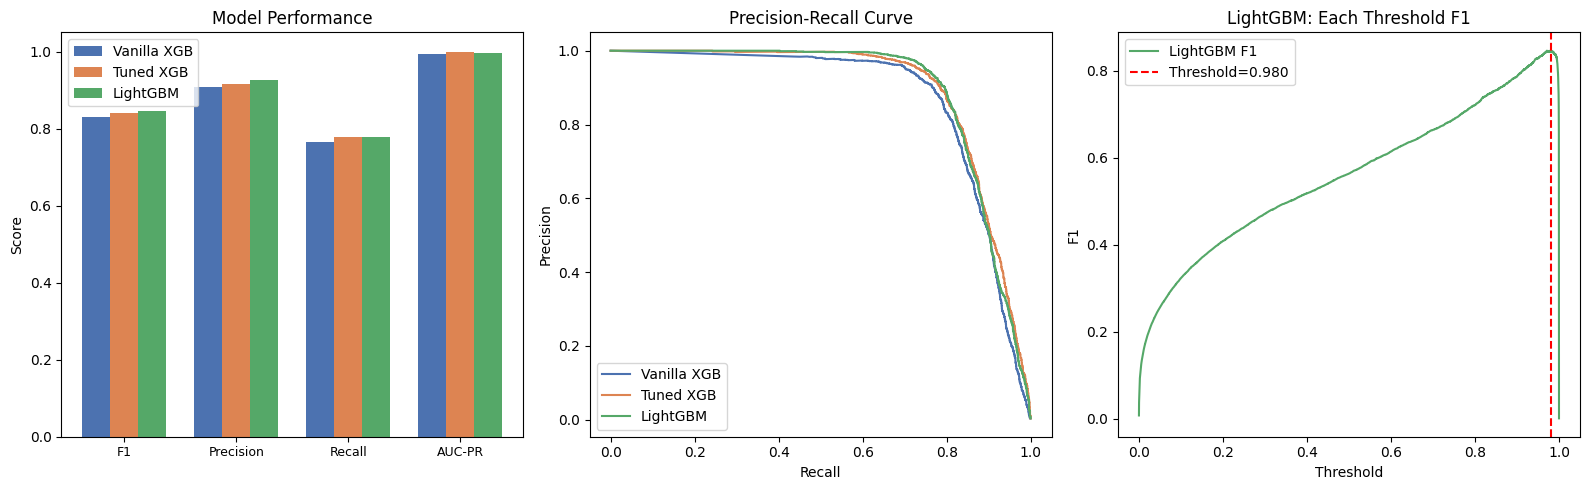


▶ 최종 선택: LightGBM   (F1=0.8456)


In [ ]:
results = pd.DataFrame({
    '모델':       ['Vanilla XGB', 'Tuned XGB', 'LightGBM'],
    'F1':  [f1_v, f1_t, f1_l],
    'Precision':  [prec_v, prec_t, prec_l],
    'Recall':     [rec_v, rec_t, rec_l],
    'ROC-AUC':     [
        roc_auc_score(y_test, y_prob_v),
        roc_auc_score(y_test, y_prob_t),
        roc_auc_score(y_test, y_prob_l),
    ],
    '임계값': [thr_v, thr_t, thr_l],
}).set_index('모델').round(4)

print(results.to_string())

# ── 시각화 ──
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (A) 지표 막대 그래프
metrics = ['F1', 'Precision', 'Recall', 'ROC-AUC']
x = np.arange(len(metrics))
w = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']
for i, (model, row) in enumerate(results.iterrows()):
    axes[0].bar(x + i*w, [row[m] for m in metrics], w, label=model, color=colors[i])
axes[0].set_xticks(x + w)
axes[0].set_xticklabels(metrics, fontsize=9)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Model Performance')
axes[0].legend()
axes[0].set_ylabel('Score')

# (B) Precision-Recall 곡선
for y_prob, label, color in [
    (y_prob_v, 'Vanilla XGB', colors[0]),
    (y_prob_t, 'Tuned XGB',   colors[1]),
    (y_prob_l, 'LightGBM',    colors[2]),
]:
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    axes[1].plot(rec, prec, label=label, color=color)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

# (C) F1 vs Threshold (최종 선택 모델)
prec_arr, rec_arr, thr_arr = precision_recall_curve(y_test, y_prob_l)
f1_arr = 2 * prec_arr * rec_arr / (prec_arr + rec_arr + 1e-9)
axes[2].plot(thr_arr, f1_arr[:-1], color=colors[2], label='LightGBM F1')
axes[2].axvline(thr_l, color='red', linestyle='--', label=f'Threshold={thr_l:.3f}')
axes[2].set_xlabel('Threshold'); axes[2].set_ylabel('F1')
axes[2].set_title('LightGBM: Each Threshold F1')
axes[2].legend()

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n▶ 최종 선택:", results['F1'].idxmax(),
      f"  (F1={results['F1'].max():.4f})")


> **Note:** the bar chart above was rendered before the label fix — its "AUC-PR" bar is the **ROC-AUC** (`roc_auc_score`). The true PR-AUC (average precision) on the hold-out set is ~0.89 for the tuned XGBoost, as shown by the `validation_0-aucpr` log in section 5-2.


## 7. 피처 중요도 비교

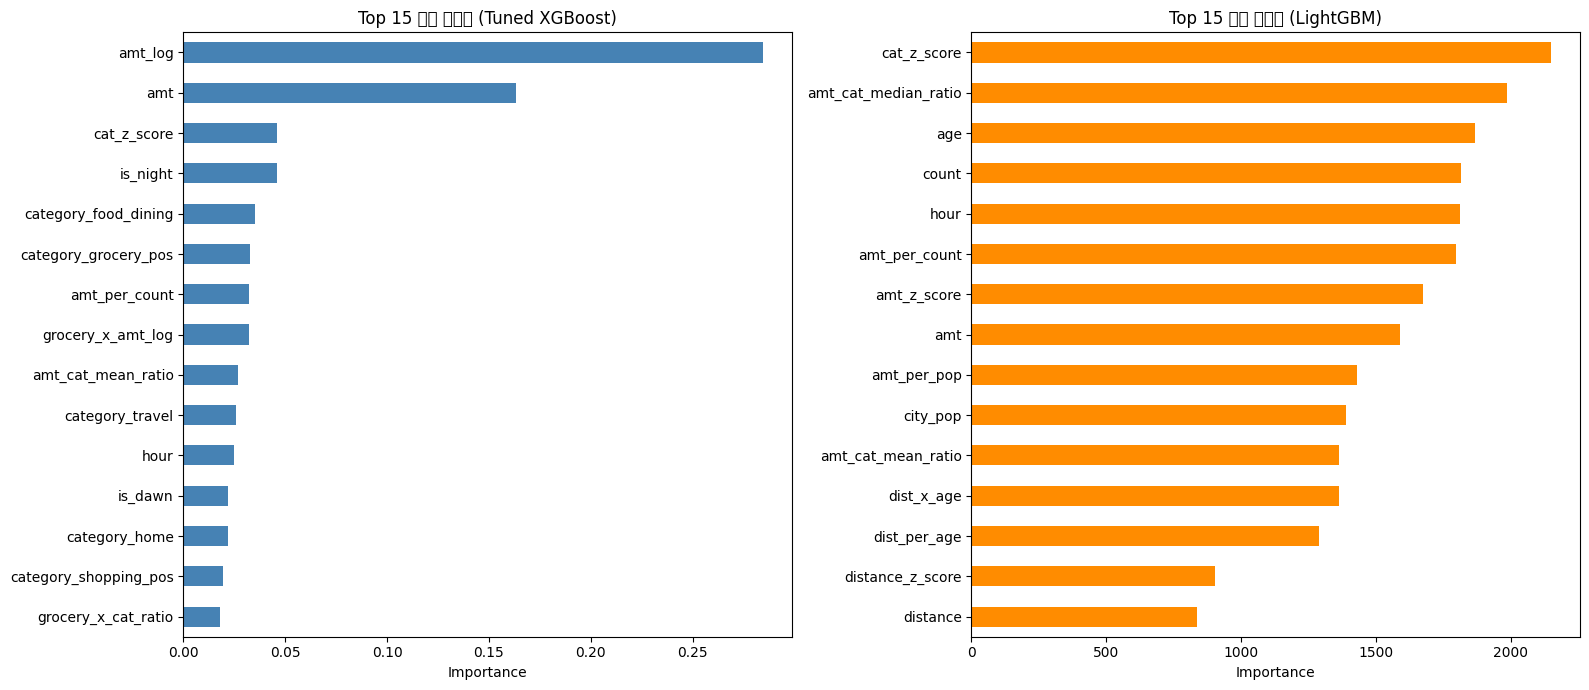

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model, title, color in [
    (axes[0], xgb_tuned, 'Tuned XGBoost', 'steelblue'),
    (axes[1], lgbm,      'LightGBM',      'darkorange'),
]:
    imp = pd.Series(model.feature_importances_, index=X_train.columns)
    top15 = imp.sort_values(ascending=False).head(15)
    top15.sort_values().plot(kind='barh', ax=ax, color=color)
    ax.set_title(f'Top 15 피처 중요도 ({title})')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. 최종 평가 (최고 성능 모델)

최종 모델: LightGBM  (임계값=0.9803)
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.93      0.78      0.85      2012

    accuracy                           1.00    525661
   macro avg       0.96      0.89      0.92    525661
weighted avg       1.00      1.00      1.00    525661



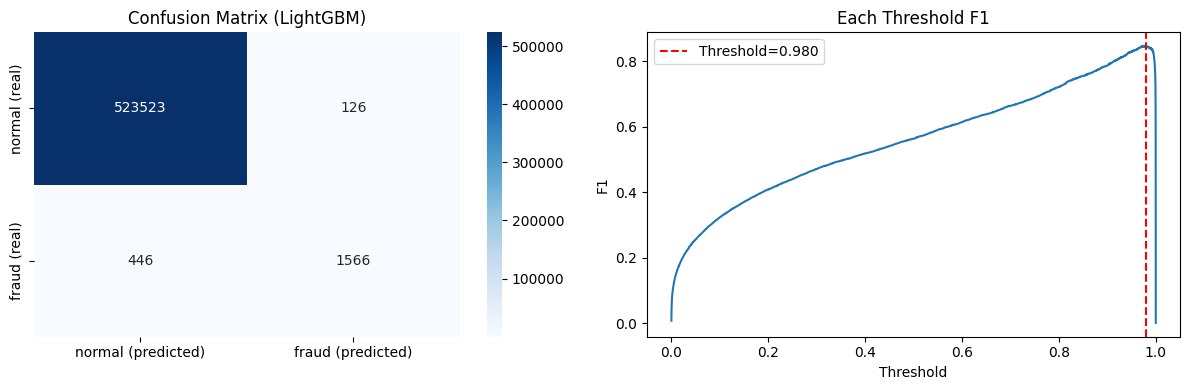


모델 비교 요약:
                 F1  Precision  Recall  ROC-AUC     임계값
모델                                                    
Vanilla XGB  0.8302     0.9084  0.7644  0.9947  0.5750
Tuned XGB    0.8413     0.9168  0.7773  0.9979  0.9826
LightGBM     0.8456     0.9255  0.7783  0.9972  0.9803


In [ ]:
# 최고 F1 모델 자동 선택
best_name = results['F1'].idxmax()
model_map = {
    'Vanilla XGB': (xgb_vanilla, y_prob_v, thr_v, y_pred_v),
    'Tuned XGB':   (xgb_tuned,   y_prob_t, thr_t, y_pred_t),
    'LightGBM':    (lgbm,        y_prob_l, thr_l, y_pred_l),
}
best_model, best_prob, best_thr, best_pred = model_map[best_name]

print("=" * 50)
print(f"최종 모델: {best_name}  (임계값={best_thr:.4f})")
print("=" * 50)
print(classification_report(y_test, best_pred, target_names=['정상', '사기']))

cm = confusion_matrix(y_test, best_pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['normal (predicted)', 'fraud (predicted)'],
            yticklabels=['normal (real)', 'fraud (real)'])
axes[0].set_title(f'Confusion Matrix ({best_name})')

# 임계값 F1 곡선
prec_b, rec_b, thr_b = precision_recall_curve(y_test, best_prob)
f1_b = 2 * prec_b * rec_b / (prec_b + rec_b + 1e-9)
axes[1].plot(thr_b, f1_b[:-1])
axes[1].axvline(best_thr, color='red', linestyle='--',
                label=f'Threshold={best_thr:.3f}')
axes[1].set_xlabel('Threshold'); axes[1].set_ylabel('F1')
axes[1].set_title('Each Threshold F1'); axes[1].legend()

plt.tight_layout()
plt.savefig('final_eval.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n모델 비교 요약:")
print(results.to_string())
